# Action-Angle Coordinates: Adiabatic Deformation (AdiabaticApprox)

Actions are adiabatic invariants: when a potential changes slowly, the actions of an orbit do not change. `actionAngleAdiabaticApprox` uses this to compute action-angle coordinates in *any* potential: it integrates each phase-space point while the potential is slowly deformed into an auxiliary potential in which actions and angles are easy to compute, and returns the actions and angles of the end point there. The only approximation is the finite duration of the deformation, set by `tintJ`, and the transformation is canonical for any duration.

`actionAngleAdiabaticApproxInverse` is the inverse transformation, from actions and angles to phase-space points: it starts from the torus of the auxiliary potential and undoes the deformation.

The method works well when the auxiliary potential is similar enough to the target potential that the orbit does not cross strong resonances during the deformation. For galactic disks and halos, a Staeckel potential that approximates the target potential is a good choice; an isochrone works for spherical potentials.

In [1]:
%matplotlib inline
import numpy
import matplotlib.pyplot as plt
import warnings
from galpy.orbit import Orbit
from galpy.potential import MWPotential2014

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)

## The idea: watching an orbit deform

Before using the classes, let us look at what the deformation does. We take an orbit in a spherical NFW potential and the points along one radial period of it, which trace a closed curve in the plane of radius and radial velocity. We then integrate all of these points while the potential changes smoothly from the NFW potential to an isochrone potential (one that is much more concentrated than a good auxiliary would be, to make the change easy to see), using two `DehnenSmoothWrapperPotential`s that switch the one off and the other on over a time `tdeform`:

In [2]:
from galpy.actionAngle import actionAngleIsochrone, actionAngleIsochroneInverse
from galpy.potential import (
    DehnenSmoothWrapperPotential,
    IsochronePotential,
    NFWPotential,
)

nfw = NFWPotential(a=2.0, normalize=1.0)
ip = IsochronePotential(b=0.2, normalize=1.0)
tdeform = 100.0
deforming = DehnenSmoothWrapperPotential(
    pot=nfw, tform=0.0, tsteady=tdeform, decay=True
) + DehnenSmoothWrapperPotential(pot=ip, tform=0.0, tsteady=tdeform, decay=False)

# the points along one radial period of an orbit
oring = Orbit([1.0, 0.6, 0.7, 0.3, 0.3, 0.0])
tphase = numpy.linspace(0.0, oring.Tr(pot=nfw, type="spherical"), 201)
oring.integrate(tphase, nfw)
ring = oring(tphase)
# ... integrated while the potential deforms
tout = numpy.linspace(0.0, tdeform, 26)
ring.integrate(tout, deforming, progressbar=False)
rs, vrs = ring.r(tout), ring.vr(tout)

# the torus of the isochrone potential with the actions of the end points
jr, lz, jz = (
    numpy.mean(j)
    for j in actionAngleIsochrone(ip=ip)(
        *(getattr(ring, q)(tdeform) for q in ("R", "vR", "vT", "z", "vz"))
    )
)
R, vR, vT, z, vz, phi = actionAngleIsochroneInverse(ip=ip)(
    jr, lz, jz, numpy.linspace(0.0, 2.0 * numpy.pi, 201), 0.0, 0.0
)
r_iso = numpy.sqrt(R**2.0 + z**2.0)
vr_iso = (R * vR + z * vz) / r_iso

Because the radial action is the area that the curve encloses (divided by $2\pi$) and actions are adiabatic invariants, the curve changes shape but keeps its area, and it ends on the torus of the isochrone potential with the same actions (dashed). The animation shows the curve during the deformation:

In [3]:
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

fig, ax = plt.subplots(figsize=(5.0, 4.0), dpi=60)
ax.plot(rs[:, 0], vrs[:, 0], "-", lw=1.0, label="orbit in the NFW potential")
(current,) = ax.plot([], [], "-", lw=2.0, label="during the deformation")
ax.plot(r_iso, vr_iso, "--", color="0.4", label="isochrone torus, same actions")
ax.set_xlabel(r"$r$")
ax.set_ylabel(r"$v_r$")
ax.set_ylim(1.1 * vrs.min(), 1.9 * vrs.max())
ax.legend(frameon=False, loc="upper right", fontsize=9)
fig.tight_layout()


def update(ii):
    current.set_data(rs[:, ii], vrs[:, ii])
    return (current,)


anim = FuncAnimation(fig, update, frames=len(tout), interval=120, blit=True)
plt.close(fig)
HTML(anim.to_jshtml(default_mode="loop"))

`actionAngleAdiabaticApprox` does exactly this for each phase-space point and reads off the actions and angles in the auxiliary potential at the end; `actionAngleAdiabaticApproxInverse` runs the deformation in reverse, starting from the dashed torus.

## Setup

We compute actions in `MWPotential2014`. As the auxiliary potential we use the Staeckel potential that `OblateStaeckelWrapperPotential` builds from `MWPotential2014` (it agrees with it in the midplane and along a reference curve), for which `actionAngleStaeckel` is exact.

<div class="alert alert-info">

**Use one fixed Staeckel potential**

A proper action-angle transformation needs the *same* auxiliary potential for every point: all points of an orbit, and all orbits, have to be deformed to one and the same integrable potential. The auxiliary is therefore a single Staeckel potential with a fixed focal length `delta` and reference curve `u0`, with `actionAngleStaeckel` set up for that potential. This is what distinguishes the method from the Staeckel approximation of `actionAngleStaeckel(pot=MWPotential2014, ...)`, which in effect uses a different Staeckel potential at each point (and can be given a different `delta` for each point): its actions vary along an orbit and are not those of one canonical transformation.

</div>

The auxiliary potential is specified through the action-angle instance `aA=` that computes its actions:

In [4]:
from galpy.actionAngle import actionAngleAdiabaticApprox, actionAngleStaeckel
from galpy.potential import OblateStaeckelWrapperPotential

delta = 0.45
aux = OblateStaeckelWrapperPotential(pot=MWPotential2014, delta=delta, u0=1.0)
aAaux = actionAngleStaeckel(pot=aux, delta=delta, c=True)
aAA = actionAngleAdiabaticApprox(pot=MWPotential2014, aA=aAaux, tintJ=100.0)

`tintJ` is the duration of the deformation (in galpy's internal time units unless given as a `Quantity`). Like the other orbit-integration-based methods, `actionAngleAdiabaticApprox` requires the azimuth `phi` and returns arrays even for single inputs:

In [5]:
o = Orbit([1.0, 0.3, 0.9, 0.3, 0.5, 0.5])
jr, lz, jz = aAA(o)
print(f"J_R = {jr[0]:.6f}, L_z = {lz[0]:.6f}, J_z = {jz[0]:.6f}")

J_R = 0.077967, L_z = 0.900000, J_z = 0.129140


## Accuracy: actions along an orbit

Actions are constant along an orbit, so their scatter along an orbit measures their accuracy. We compare with the Staeckel approximation (`actionAngleStaeckel` applied to `MWPotential2014` itself) for this thick-disk-like orbit. The top panels show the actions from both methods; the scatter of the adiabatic actions is too small to see there, so the bottom panels show them alone, relative to their mean:

Staeckel : relative scatter of J_R = 2.3e-02, of J_z = 1.1e-02
adiabatic: relative scatter of J_R = 2.7e-05, of J_z = 1.7e-05


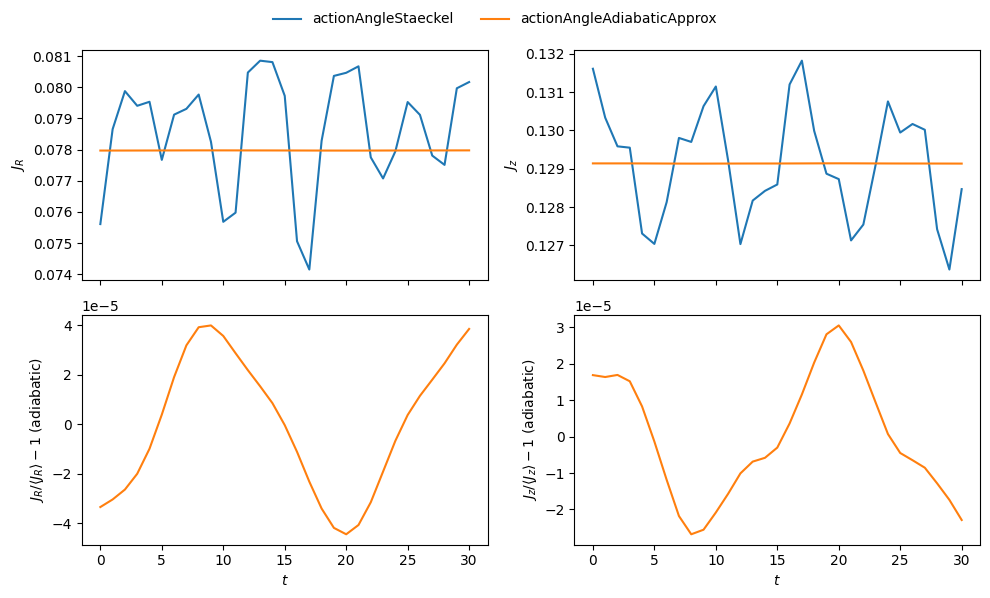

In [6]:
ts = numpy.linspace(0.0, 30.0, 31)
o.integrate(ts, MWPotential2014)
args = (o.R(ts), o.vR(ts), o.vT(ts), o.z(ts), o.vz(ts), o.phi(ts))

aAS = actionAngleStaeckel(pot=MWPotential2014, delta=delta, c=True)
js_staeckel = aAS(*args)
js_adiabatic = aAA(*args)

fig, axes = plt.subplots(2, 2, figsize=(10, 6.0), sharex=True)
for jj, ii, label in zip((0, 1), (0, 2), (r"J_R", r"J_z")):
    axes[0, jj].plot(ts, js_staeckel[ii], label="actionAngleStaeckel")
    axes[0, jj].plot(ts, js_adiabatic[ii], label="actionAngleAdiabaticApprox")
    axes[0, jj].set_ylabel(f"${label}$")
    axes[1, jj].plot(
        ts, js_adiabatic[ii] / numpy.mean(js_adiabatic[ii]) - 1.0, color="C1"
    )
    axes[1, jj].set_ylabel(rf"${label} / \langle {label} \rangle - 1$ (adiabatic)")
    axes[1, jj].set_xlabel(r"$t$")
fig.legend(
    *axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False
)
plt.tight_layout(rect=(0.0, 0.0, 1.0, 0.95))

for name, js in (("Staeckel ", js_staeckel), ("adiabatic", js_adiabatic)):
    print(
        f"{name}: relative scatter of J_R = {numpy.std(js[0]) / numpy.mean(js[0]):.1e}, "
        f"of J_z = {numpy.std(js[2]) / numpy.mean(js[2]):.1e}"
    )

For this orbit and `tintJ=100`, the actions of the adiabatic deformation scatter by a few parts in $10^5$ along the orbit, against a percent for the Staeckel approximation. The next section shows how this depends on `tintJ`.

## Convergence with the duration of the deformation

The longer the deformation, the better the actions are conserved during it. A deformation over a few radial periods already improves on the Staeckel approximation, and the error keeps falling for longer deformations (the radial period of this orbit is about 6). Because the scatter along an orbit is so easy to compute, it is good practice to check it for the orbits of interest: orbits close to a low-order resonance, for example with nearly equal radial and vertical frequencies, can fail to converge.

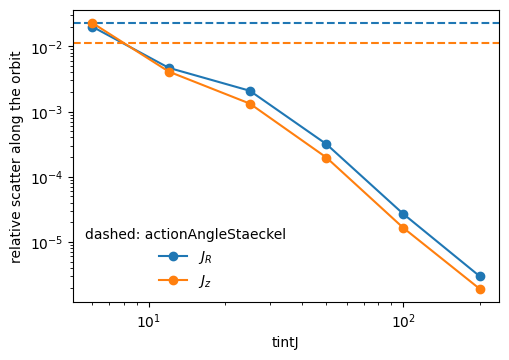

In [7]:
tintJs = numpy.array([6.0, 12.0, 25.0, 50.0, 100.0, 200.0])
scatter = numpy.empty((len(tintJs), 2))
for ii, tintJ in enumerate(tintJs):
    js = actionAngleAdiabaticApprox(pot=MWPotential2014, aA=aAaux, tintJ=tintJ)(*args)
    scatter[ii] = [numpy.std(js[kk]) / numpy.mean(js[kk]) for kk in (0, 2)]

plt.figure(figsize=(5.5, 3.8))
for kk, ii, label in zip((0, 1), (0, 2), (r"$J_R$", r"$J_z$")):
    (line,) = plt.loglog(tintJs, scatter[:, kk], "o-", label=label)
    plt.axhline(
        numpy.std(js_staeckel[ii]) / numpy.mean(js_staeckel[ii]),
        color=line.get_color(),
        ls="--",
    )
plt.xlabel("tintJ")
plt.ylabel("relative scatter along the orbit")
plt.legend(frameon=False, title="dashed: actionAngleStaeckel");

## Frequencies and angles

`actionsFreqs` and `actionsFreqsAngles` also return the frequencies and the angles. By default (`npoints=2`), each point is transformed together with two points a short time (`npoints_dt`) before and after it along its orbit; the frequencies are the rate at which the angles of these points advance, and the actions are averaged over them.

In [8]:
jr, lz, jz, Or, Op, Oz, ar, ap, az = aAA.actionsFreqsAngles(*args)
print(
    f"Omega_R = {numpy.mean(Or):.5f} +/- {numpy.std(Or):.5f}, "
    f"Omega_phi = {numpy.mean(Op):.5f} +/- {numpy.std(Op):.5f}, "
    f"Omega_z = {numpy.mean(Oz):.5f} +/- {numpy.std(Oz):.5f}"
)

Omega_R = 1.08055 +/- 0.00003, Omega_phi = 0.77386 +/- 0.00003, Omega_z = 0.92848 +/- 0.00008


Along an orbit, the angles increase linearly in time at these frequencies. The residuals from that linear increase are small:

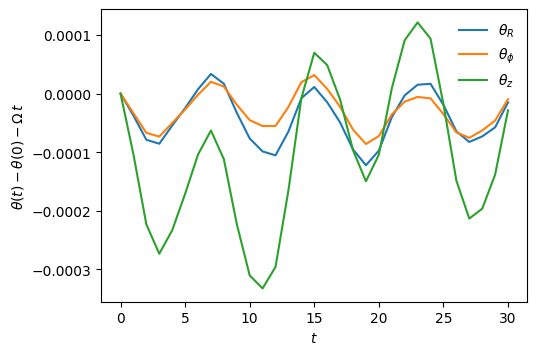

In [9]:
def wrap(x):
    return (x + numpy.pi) % (2.0 * numpy.pi) - numpy.pi


fig, ax = plt.subplots(figsize=(5.5, 3.8))
for ang, Om, label in zip(
    (ar, ap, az), (Or, Op, Oz), (r"$\theta_R$", r"$\theta_\phi$", r"$\theta_z$")
):
    resid = wrap(ang - numpy.mean(Om) * ts)
    ax.plot(ts, wrap(resid - resid[0]), label=label)
ax.set_xlabel(r"$t$")
ax.set_ylabel(r"$\theta(t) - \theta(0) - \Omega\,t$")
ax.legend(frameon=False);

### The zero point of the angles

The angles that `actionAngleAdiabaticApprox` returns by default are proper angle coordinates on the torus: they advance at the orbital frequencies. However, they differ from the angles of the usual convention (zero radial angle at pericenter, zero vertical angle when moving upward through the plane) by an offset that is constant on each torus. **For many applications this does not matter**: for example for anything that only uses differences of angles on a torus, uniform sampling of tori, or any use together with `actionAngleAdiabaticApproxInverse`.

If you do need the usual convention, set `calibrate_angles=True`. The offset of each point's torus is then measured with a round trip of the transformation, which makes the calculation three times as expensive. Here we compare with the angles of `actionAngleStaeckel`, which follow the usual convention (and are themselves approximate):

In [10]:
aAA_cal = actionAngleAdiabaticApprox(
    pot=MWPotential2014, aA=aAaux, tintJ=100.0, calibrate_angles=True
)
ang_cal = numpy.array(aAA_cal.actionsFreqsAngles(*args)[6:])
ang_staeckel = numpy.array(aAS.actionsFreqsAngles(*args)[6:])
ang_raw = numpy.array([ar, ap, az])
print(
    "default angles minus Staeckel angles (first point):   ",
    wrap(ang_raw - ang_staeckel)[:, 0].round(3),
)
print(
    "calibrated angles minus Staeckel angles (first point):",
    wrap(ang_cal - ang_staeckel)[:, 0].round(3),
)
print(
    "largest difference along the orbit (calibrated):      ",
    numpy.amax(numpy.fabs(wrap(ang_cal - ang_staeckel)), axis=1).round(3),
)

default angles minus Staeckel angles (first point):    [0.758 1.661 0.815]
calibrated angles minus Staeckel angles (first point): [-0.017  0.005 -0.02 ]
largest difference along the orbit (calibrated):       [0.021 0.013 0.028]


With `npoints=0`, each point is transformed on its own. This is the plain, exactly canonical transformation, at a third of the cost; it returns actions and angles, but no frequencies:

In [11]:
aAA0 = actionAngleAdiabaticApprox(pot=MWPotential2014, aA=aAaux, tintJ=100.0, npoints=0)
jr0, lz0, jz0, _, _, _, ar0, ap0, az0 = aAA0.actionsFreqsAngles(o)
print(f"J_R = {jr0[0]:.6f}, L_z = {lz0[0]:.6f}, J_z = {jz0[0]:.6f}")
print(f"theta_R = {ar0[0]:.4f}, theta_phi = {ap0[0]:.4f}, theta_z = {az0[0]:.4f}")

J_R = 0.077967, L_z = 0.900000, J_z = 0.129140
theta_R = 1.7199, theta_phi = 1.7436, theta_z = 1.0064


## The inverse: from actions and angles to phase-space points

`actionAngleAdiabaticApproxInverse` needs an inverse action-angle instance `aAI=` for the auxiliary potential: `actionAngleIsochroneInverse`, `actionAngleSphericalInverse`, or `actionAngleStaeckelInverse`. For the Staeckel potential above, this is `actionAngleStaeckelInverse` (see the Staeckel inverse tutorial); here we set it up for the torus with the actions that we just computed. The inverse can be set up directly from the `actionAngleAdiabaticApprox` instance with `aAA=`, which passes on the potential, the duration, and the integration settings:

In [12]:
from galpy.actionAngle import (
    actionAngleAdiabaticApproxInverse,
    actionAngleStaeckelInverse,
)

aAIaux = actionAngleStaeckelInverse(
    pot=aux, delta=delta, jrs=jr0, Lzs=lz0, jzs=jz0, mm_npt=256, progressbar=False
)
aAAI = actionAngleAdiabaticApproxInverse(aAA=aAA0, aAI=aAIaux)
xv = aAAI(jr0, lz0, jz0, ar0, ap0, az0)
print("returned point:", numpy.array(xv)[:, 0].round(6))
print(
    "original point:",
    numpy.array([o.R(), o.vR(), o.vT(), o.z(), o.vz(), o.phi()]).round(6),
)

returned point: [1.  0.3 0.9 0.3 0.5 0.5]
original point: [1.  0.3 0.9 0.3 0.5 0.5]


The two transformations are exact inverses of each other (to the precision of the orbit integration) for the same `tintJ`, whatever its value. With the inverse, we can populate the torus of the orbit: we draw angles uniformly and compare the resulting points with the integrated orbit in the meridional plane:

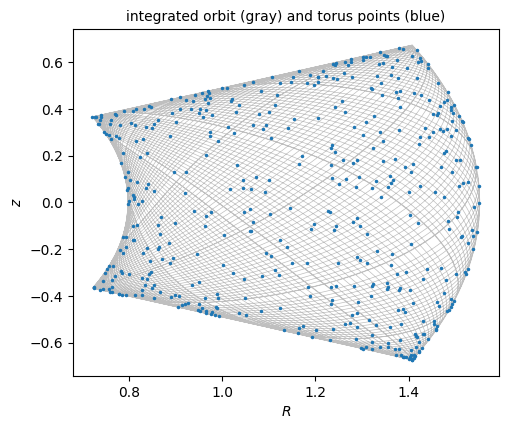

In [13]:
rng = numpy.random.default_rng(1)
angles = rng.uniform(0.0, 2.0 * numpy.pi, (3, 500))
R, vR, vT, z, vz, phi = aAAI(jr0, lz0, jz0, *angles)

tlong = numpy.linspace(0.0, 400.0, 20001)
olong = o()
olong.integrate(tlong, MWPotential2014)

plt.figure(figsize=(5.5, 4.5))
plt.plot(olong.R(tlong), olong.z(tlong), "-", color="0.75", lw=0.5)
plt.plot(R, z, ".", ms=3)
plt.xlabel(r"$R$")
plt.ylabel(r"$z$")
plt.title("integrated orbit (gray) and torus points (blue)", fontsize=10);

## Choosing the auxiliary potential

The auxiliary potential has to be close enough to the target potential for the orbit's frequencies to stay clear of strong resonances during the deformation. For spherical potentials, an isochrone works very well. Its scale `b` can be set with `estimateBIsochrone`, which returns the smallest, median, and largest `b` of the isochrone potentials that match the target potential at the points given, here along the orbit; the precise value matters little:

In [14]:
from galpy.actionAngle import actionAngleSpherical, estimateBIsochrone

on = Orbit([1.0, 0.4, 0.8, 0.3, 0.3, 0.0])
on.integrate(ts, nfw)
nargs = (on.R(ts), on.vR(ts), on.vT(ts), on.z(ts), on.vz(ts), on.phi(ts))
bmin, bmed, bmax = estimateBIsochrone(nfw, on.R(ts), on.z(ts))
print(f"estimateBIsochrone: b between {bmin:.2f} and {bmax:.2f}, median {bmed:.2f}")
jr_true = actionAngleSpherical(pot=nfw)(*nargs)[0]
for tintJ in (25.0, 50.0, 100.0):
    aAn = actionAngleAdiabaticApprox(
        pot=nfw, aA=actionAngleIsochrone(b=bmed), tintJ=tintJ
    )
    err = numpy.amax(numpy.fabs(aAn(*nargs)[0] / jr_true - 1.0))
    print(f"tintJ = {tintJ:5.0f}: largest relative error of J_R = {err:.1e}")

estimateBIsochrone: b between 0.53 and 0.89, median 0.76


tintJ =    25: largest relative error of J_R = 6.1e-05


tintJ =    50: largest relative error of J_R = 3.0e-06


tintJ =   100: largest relative error of J_R = 7.4e-07


For a flattened potential such as `MWPotential2014`, however, the deformation to a spherical potential sweeps disk orbits across resonances between the radial and vertical frequencies, and the actions stop improving. For the thick-disk orbit above:

In [15]:
for tintJ in (25.0, 100.0, 400.0):
    js = actionAngleAdiabaticApprox(
        pot=MWPotential2014, aA=actionAngleIsochrone(b=0.8), tintJ=tintJ
    )(*args)
    print(
        f"tintJ = {tintJ:5.0f}: relative scatter of J_R = {numpy.std(js[0]) / numpy.mean(js[0]):.1e}, "
        f"of J_z = {numpy.std(js[2]) / numpy.mean(js[2]):.1e}"
    )

tintJ =    25: relative scatter of J_R = 1.3e-02, of J_z = 1.5e-02


tintJ =   100: relative scatter of J_R = 6.0e-04, of J_z = 5.1e-04


tintJ =   400: relative scatter of J_R = 1.0e-03, of J_z = 8.1e-04


The scatter stalls at about a part in a thousand, while it keeps falling for the Staeckel auxiliary potential in the convergence figure above. As a rule: use `actionAngleIsochrone` or `actionAngleSpherical` as `aA=` for (nearly) spherical potentials and `actionAngleStaeckel` for an `OblateStaeckelWrapperPotential` of the target for flattened ones. A small number of orbits that are trapped at a resonance in the target potential do not converge for any auxiliary potential, as for all methods that assume that orbits are regular tori of the standard kind.

## Non-axisymmetric potentials

Nothing in the method refers to the symmetry of the target potential. For example, for a mildly triaxial halo around the disk and bulge of `MWPotential2014`, the same axisymmetric Staeckel auxiliary potential gives three actions for orbits that circulate about the short axis, including the azimuthal action that replaces the angular momentum (which is no longer conserved):

In [16]:
from galpy.potential import TriaxialNFWPotential

halo = MWPotential2014[2]
tri = MWPotential2014[:2] + TriaxialNFWPotential(amp=halo._amp, a=halo.a, b=0.9, c=1.0)
ot = Orbit([1.0, 0.15, 1.0, 0.1, 0.15, 0.5])
ot.integrate(ts, tri)
targs = (ot.R(ts), ot.vR(ts), ot.vT(ts), ot.z(ts), ot.vz(ts), ot.phi(ts))
jst = actionAngleAdiabaticApprox(pot=tri, aA=aAaux, tintJ=200.0)(*targs)
Lz = ot.R(ts) * ot.vT(ts)
print(f"L_z along the orbit:   {numpy.mean(Lz):.4f} +/- {numpy.std(Lz):.4f}")
for label, js in zip(("J_R  ", "J_phi", "J_z  "), jst):
    print(f"{label} along the orbit: {numpy.mean(js):.5f} +/- {numpy.std(js):.5f}")

L_z along the orbit:   0.9984 +/- 0.0068
J_R   along the orbit: 0.00897 +/- 0.00002
J_phi along the orbit: 0.99822 +/- 0.00004
J_z   along the orbit: 0.01510 +/- 0.00004


Orbits of other families (box orbits, long-axis tubes) have no counterpart in an axisymmetric auxiliary potential and do not converge.

## Summary

- `actionAngleAdiabaticApprox(pot=, aA=, tintJ=)` computes actions, frequencies, and angles in any potential by slowly deforming it into the potential of `aA=`; longer `tintJ` is more accurate and more expensive.
- The auxiliary potential should resemble the target, and it has to be one fixed potential: a Staeckel wrapper of the target with a fixed focal length for flattened potentials, an isochrone (with `b` from `estimateBIsochrone`) for spherical ones.
- The default angles differ from the usual convention by an offset that is constant on each torus; `calibrate_angles=True` removes it at three times the cost.
- `npoints=0` gives the plain canonical transformation without frequencies.
- `actionAngleAdiabaticApproxInverse` is the exact inverse for the same `tintJ`, also with `calibrate_angles=True` on both.